# Economic Data Analysis: Predicting Unemployment Rate Using Economic Indicators

**Author:** Machine Learning Student  
**Project:** College ML Regression Project  
**Dataset:** World Bank World Development Indicators (WDI) (1995–2023)  

---

### Project Overview
The objective of this project is to analyze macroeconomic indicators and predict national **Unemployment Rate (%)** using machine learning regression techniques.

In this notebook, we perform:
1. **Data Loading & Inspection**: Examining dimensions, columns, and data types.
2. **Data Cleaning & Quality Check**: Analyzing missing values, duplicates, and unique country coverage.
3. **Summary Statistics**: Calculating measures of central tendency and dispersion.
4. **Exploratory Data Analysis (EDA)**: Visualizing feature distributions, correlations, scatter plots against unemployment, and time-series trends.
5. **Economic Insights**: Explaining what the data reveals about unemployment dynamics.


In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic suitable for student project
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
PEACH = '#F4B6A6'
DARK_TEXT = '#3D302C'

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load Dataset
We load the real-world dataset stored in `../data/economic_data.csv`. This data was sourced directly from the World Bank DataBank API.


In [2]:
# Load CSV
df = pd.read_csv('../data/economic_data.csv')

# Display first 5 rows
df.head()


,Country,Country_Code,Year,GDP_Growth,GDP_Per_Capita,Inflation_Rate,Population,Real_Interest_Rate,Unemployment_Rate
0,Afghanistan,AFG,1995,NaN,NaN,NaN,17065836.0,NaN,7.868
1,Afghanistan,AFG,1996,NaN,NaN,NaN,17763266.0,NaN,7.878
2,Afghanistan,AFG,1997,NaN,NaN,NaN,18452091.0,NaN,7.863
3,Afghanistan,AFG,1998,NaN,NaN,NaN,19159996.0,NaN,7.869
4,Afghanistan,AFG,1999,NaN,NaN,NaN,19887785.0,NaN,7.877


In [3]:
# Display last 5 rows
df.tail()


,Country,Country_Code,Year,GDP_Growth,GDP_Per_Capita,Inflation_Rate,Population,Real_Interest_Rate,Unemployment_Rate
7535,Zimbabwe,ZWE,2019,-6.332450,2184.521554,255.304991,15271368.0,-76.631576,7.373
7536,Zimbabwe,ZWE,2020,-7.816951,2059.637040,557.201817,15526888.0,-80.610262,8.617
7537,Zimbabwe,ZWE,2021,8.468017,2613.616741,98.546105,15797210.0,-30.318195,9.540
7538,Zimbabwe,ZWE,2022,6.139263,2536.401971,104.705171,16069056.0,-38.093651,10.087
7539,Zimbabwe,ZWE,2023,5.350869,2195.225020,NaN,16340822.0,-68.877267,9.348


## 2. Dataset Dimensions, Columns, & Types
Let's inspect the shape, column names, and data types of each indicator.


In [4]:
# Dataset shape
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")


Dataset Shape: 7540 rows, 9 columns


In [5]:
# Column names and non-null types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7540 entries, 0 to 7539
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             7540 non-null   object 
 1   Country_Code        7540 non-null   object 
 2   Year                7540 non-null   int64  
 3   GDP_Growth          7203 non-null   float64
 4   GDP_Per_Capita      7292 non-null   float64
 5   Inflation_Rate      6376 non-null   float64
 6   Population          7540 non-null   float64
 7   Real_Interest_Rate  3489 non-null   float64
 8   Unemployment_Rate   6666 non-null   float64
dtypes: float64(6), int64(1), object(2)
memory usage: 530.3+ KB


## 3. Data Cleaning & Integrity Check
Here we check for missing values, duplicate rows, unique countries, and the year range.


In [6]:
# Check duplicate rows
duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}")


Total duplicate rows: 0


In [7]:
# Missing value counts and percentages
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Values': missing_counts, 'Percentage (%)': missing_pct.round(2)})
missing_df


,Missing_Values,Percentage (%)
Country,0,0.00
Country_Code,0,0.00
Year,0,0.00
GDP_Growth,337,4.47
GDP_Per_Capita,248,3.29
Inflation_Rate,1164,15.44
Population,0,0.00
Real_Interest_Rate,4051,53.73
Unemployment_Rate,874,11.59


In [8]:
# Country and Year coverage
print(f"Total unique countries: {df['Country'].nunique()}")
print(f"Time period: {df['Year'].min()} to {df['Year'].max()}")


Total unique countries: 260
Time period: 1995 to 2023


## 4. Summary Statistics
We calculate statistical summaries (mean, standard deviation, percentiles) for numerical features.


In [9]:
# Summary statistics for numeric columns
df.describe().round(2)


,Year,GDP_Growth,GDP_Per_Capita,Inflation_Rate,Population,Real_Interest_Rate,Unemployment_Rate
count,7540.00,7203.00,7292.00,6376.00,7.540000e+03,3489.00,6666.00
mean,2009.00,3.56,13607.90,8.90,2.549602e+08,6.11,7.90
std,8.37,5.98,22186.81,67.73,8.567489e+08,11.74,5.58
min,1995.00,-54.40,62.14,-16.86,9.280000e+03,-93.51,0.10
25%,2002.00,1.55,1350.18,1.96,1.329146e+06,2.07,4.09
50%,2009.00,3.73,4360.85,3.85,8.851604e+06,5.77,6.38
75%,2016.00,5.84,16674.18,7.17,4.832448e+07,10.02,10.20
max,2023.00,149.97,256799.91,4145.11,8.062923e+09,139.96,38.80


## 5. Prepare Complete Observations for Modeling & Analysis
We define our 4 core economic features:
- `GDP_Growth` (Annual GDP growth %)
- `Inflation_Rate` (Consumer price inflation %)
- `Real_Interest_Rate` (Inflation-adjusted lending rate %)
- `GDP_Per_Capita` (Income level in USD)
And our target variable:
- `Unemployment_Rate` (Total unemployment as % of labor force)


In [10]:
features = ['GDP_Growth', 'Inflation_Rate', 'Real_Interest_Rate', 'GDP_Per_Capita']
target = 'Unemployment_Rate'

# Filter complete cases
clean_df = df.dropna(subset=features + [target]).copy()
print(f"Complete observations available: {len(clean_df)} rows across {clean_df['Country'].nunique()} countries.")
clean_df[features + [target]].describe().round(2)


Complete observations available: 3127 rows across 137 countries.


,GDP_Growth,Inflation_Rate,Real_Interest_Rate,GDP_Per_Capita,Unemployment_Rate
count,3127.00,3127.00,3127.00,3127.00,3127.00
mean,3.85,10.80,6.14,10024.64,7.79
std,5.61,93.11,11.66,16008.82,5.96
min,-54.40,-16.86,-93.51,108.04,0.10
25%,1.80,2.10,1.90,1210.70,3.55
50%,3.93,4.50,5.53,3838.92,5.95
75%,6.12,8.35,9.90,9887.29,10.48
max,86.83,4145.11,139.96,113122.13,37.32


## 6. Exploratory Data Analysis (EDA)

### Visualization 1: Distribution of Unemployment Rate (Target Variable)
Let's inspect how the unemployment rate is distributed across countries and years.


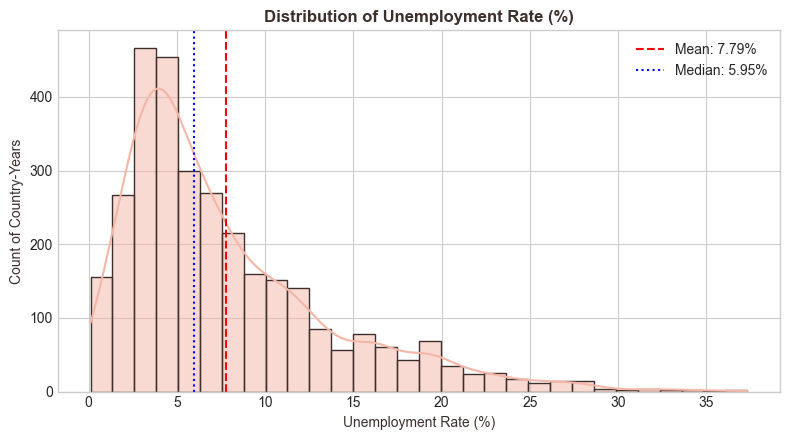

In [11]:
plt.figure(figsize=(8, 4.5))
sns.histplot(clean_df['Unemployment_Rate'], kde=True, color=PEACH, edgecolor=DARK_TEXT, bins=30)
plt.axvline(clean_df['Unemployment_Rate'].mean(), color='red', linestyle='--', label=f"Mean: {clean_df['Unemployment_Rate'].mean():.2f}%")
plt.axvline(clean_df['Unemployment_Rate'].median(), color='blue', linestyle=':', label=f"Median: {clean_df['Unemployment_Rate'].median():.2f}%")
plt.title('Distribution of Unemployment Rate (%)', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.xlabel('Unemployment Rate (%)', fontsize=10, color=DARK_TEXT)
plt.ylabel('Count of Country-Years', fontsize=10, color=DARK_TEXT)
plt.legend()
plt.tight_layout()
plt.show()


*Insight:* The distribution of unemployment rate is moderately right-skewed. Most observations cluster between 4% and 10%, while some countries experience prolonged structural unemployment exceeding 20% to 30%.


### Visualization 2: GDP Growth vs. Unemployment Rate (Okun's Law)
In macroeconomics, Okun's Law posits an inverse relationship between economic growth and unemployment.


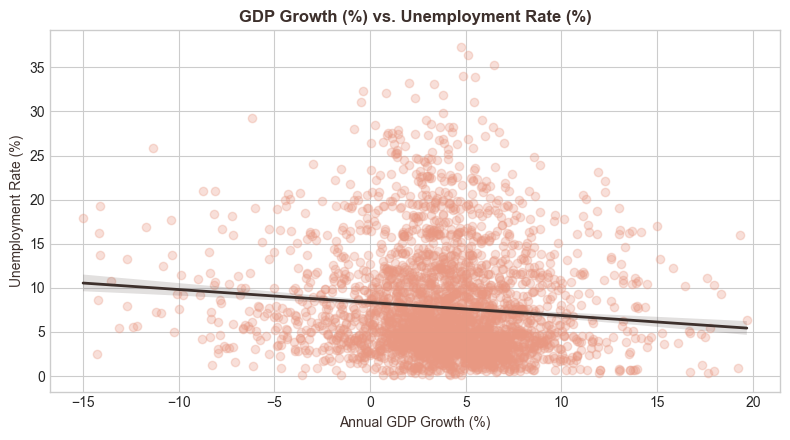

In [12]:
plt.figure(figsize=(8, 4.5))
# Clip extreme growth outliers for visual clarity
plot_gdp = clean_df[clean_df['GDP_Growth'].between(-15, 20)]
sns.regplot(data=plot_gdp, x='GDP_Growth', y='Unemployment_Rate',
            scatter_kws={'alpha': 0.3, 'color': '#E89882'},
            line_kws={'color': DARK_TEXT, 'linewidth': 2})
plt.title('GDP Growth (%) vs. Unemployment Rate (%)', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.xlabel('Annual GDP Growth (%)', fontsize=10, color=DARK_TEXT)
plt.ylabel('Unemployment Rate (%)', fontsize=10, color=DARK_TEXT)
plt.tight_layout()
plt.show()


*Insight:* We observe a slight negative regression slope, indicating that periods of higher economic expansion generally coincide with lower unemployment rates.


### Visualization 3: Inflation Rate vs. Unemployment Rate (Phillips Curve Analysis)
We examine the empirical relationship between inflation and unemployment.


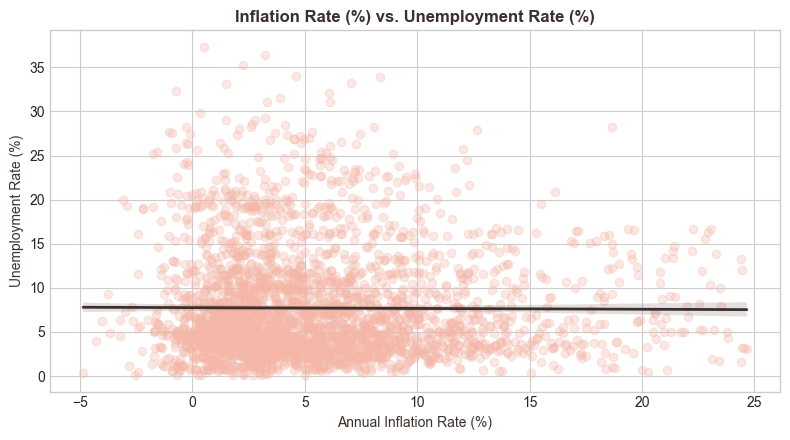

In [13]:
plt.figure(figsize=(8, 4.5))
# Filter extreme hyperinflation outliers for clear plotting
plot_inf = clean_df[clean_df['Inflation_Rate'].between(-5, 25)]
sns.regplot(data=plot_inf, x='Inflation_Rate', y='Unemployment_Rate',
            scatter_kws={'alpha': 0.3, 'color': PEACH},
            line_kws={'color': DARK_TEXT, 'linewidth': 2})
plt.title('Inflation Rate (%) vs. Unemployment Rate (%)', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.xlabel('Annual Inflation Rate (%)', fontsize=10, color=DARK_TEXT)
plt.ylabel('Unemployment Rate (%)', fontsize=10, color=DARK_TEXT)
plt.tight_layout()
plt.show()


*Insight:* In cross-country annual data, inflation and unemployment show a slight positive slope rather than a simple textbook short-run trade-off, as high inflation often reflects macroeconomic instability.


### Visualization 4: Correlation Matrix
We compute Pearson correlation coefficients across our numerical indicators.


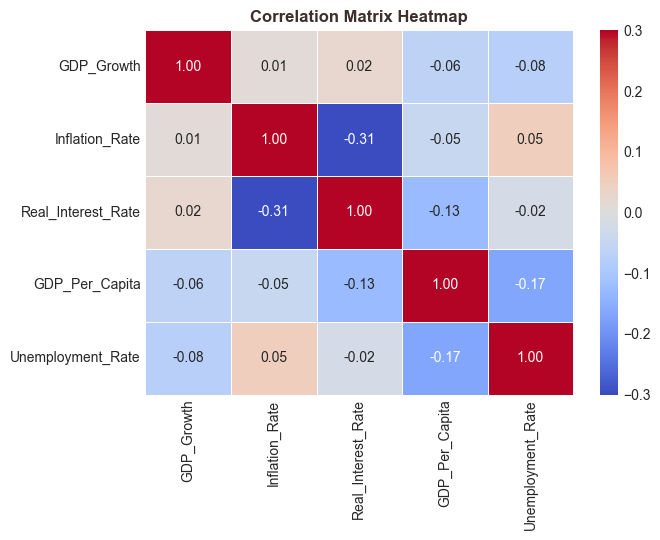

In [14]:
plt.figure(figsize=(7, 5.5))
corr_matrix = clean_df[features + [target]].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.3, vmax=0.3,
            linewidths=0.5, linecolor='white')
plt.title('Correlation Matrix Heatmap', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.tight_layout()
plt.show()


*Insight:* GDP per Capita shows the strongest negative correlation (-0.17) with unemployment, followed by GDP Growth (-0.08). The relatively modest linear correlations suggest that non-linear models (e.g. Random Forest) may capture more nuanced relationships.


### Visualization 5: Global Average Unemployment Trend (1995–2023)
Let's see how global average unemployment has fluctuated across decades, including the 2008 Financial Crisis and 2020 COVID shock.


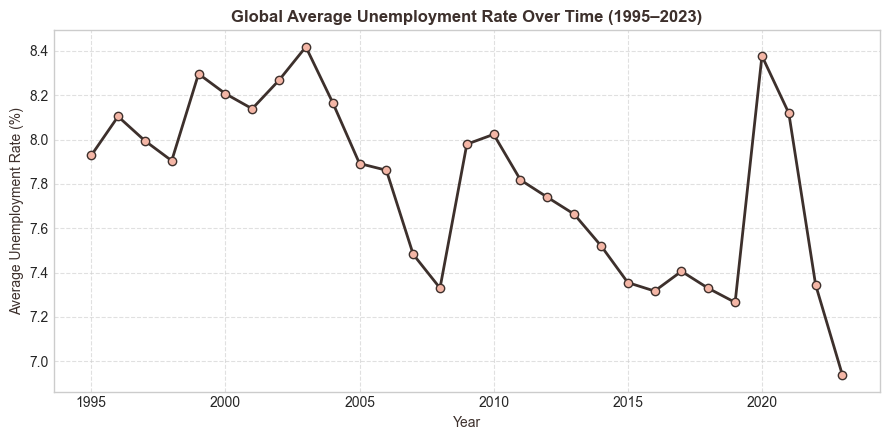

In [15]:
yearly_trend = clean_df.groupby('Year')['Unemployment_Rate'].mean().reset_index()

plt.figure(figsize=(9, 4.5))
plt.plot(yearly_trend['Year'], yearly_trend['Unemployment_Rate'], marker='o', color=DARK_TEXT, linewidth=2, markerfacecolor=PEACH)
plt.title('Global Average Unemployment Rate Over Time (1995–2023)', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.xlabel('Year', fontsize=10, color=DARK_TEXT)
plt.ylabel('Average Unemployment Rate (%)', fontsize=10, color=DARK_TEXT)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


*Insight:* We can clearly identify global macroeconomic events: peaks around the early 2000s dot-com bubble, the 2008–2010 Great Recession, and the 2020 pandemic surge.


### Visualization 6: Country-Level Unemployment Comparison (Selected Major Economies)
Comparing mean historical unemployment across diverse economies.


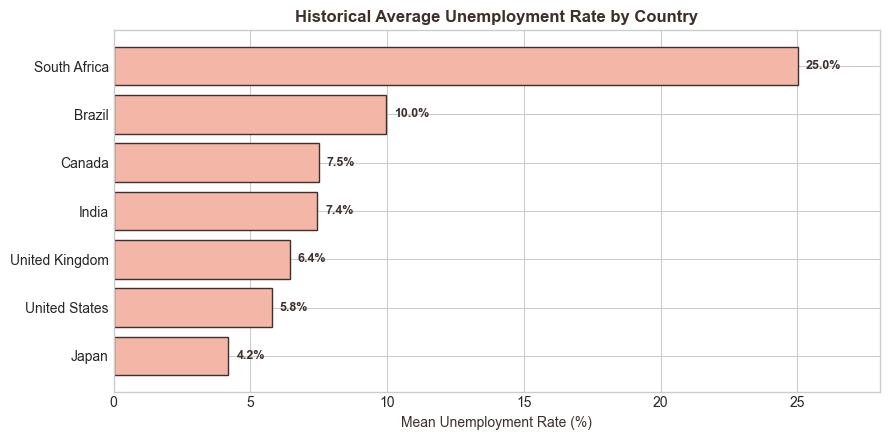

In [16]:
sample_countries = ['United States', 'Germany', 'Japan', 'United Kingdom', 'South Africa', 'Spain', 'India', 'Brazil', 'Canada']
country_sub = clean_df[clean_df['Country'].isin(sample_countries)]
country_means = country_sub.groupby('Country')['Unemployment_Rate'].mean().sort_values()

plt.figure(figsize=(9, 4.5))
bars = plt.barh(country_means.index, country_means.values, color=PEACH, edgecolor=DARK_TEXT)
plt.title('Historical Average Unemployment Rate by Country', fontsize=12, fontweight='bold', color=DARK_TEXT)
plt.xlabel('Mean Unemployment Rate (%)', fontsize=10, color=DARK_TEXT)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold', color=DARK_TEXT)

plt.xlim(0, max(country_means.values) + 3)
plt.tight_layout()
plt.show()


*Insight:* Baseline structural unemployment varies significantly across nations due to institutional and demographic differences, ranging from ~2.8% in Japan to over ~25% in South Africa.


## 7. Conclusions from Exploratory Data Analysis
1. **Target Characteristics**: Unemployment rate has a mean of ~7.8% and median of ~5.9%, with occasional high-unemployment outliers.
2. **Economic Predictors**: Higher GDP Growth and higher GDP per Capita are associated with lower unemployment, aligning with economic theory.
3. **Model Implications**: The non-linear nature of economic relationships and differing national baselines indicate that non-linear ensemble models like Random Forest and Gradient Boosting will likely outperform simple linear models.
4. **Validation Strategy**: Because data spans 1995–2023 across countries, we will test both standard random splits and time-aware evaluation strategies to ensure models do not suffer from temporal leakage.
